# NYC Yellow Taxi | Phase 2
January 2024 · Data Analysis, Fall 1405 · Aida Abbasi

This notebook inspects the published aggregates. Run `python src/phase2.py` from the phase directory with the official raw inputs to rebuild them. No forecast model is fitted here.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
out = root / 'data' / 'processed'

def table(name):
    return pd.read_csv(out / f'{name}.csv')

def show_figure(name):
    display(Image(filename=str(root / 'figures' / name), width=720))

summary = json.loads((out / 'summary.json').read_text())
display(table('cleaning_funnel'))
display(table('missingness'))
display(table('split_summary'))

,rule,removed,remaining
0,Exact duplicates,0,2964624
1,Pickup outside January or missing,18,2964606
2,Duration missing or non-positive,870,2963736
3,Duration over four hours,1878,2961858
4,Distance missing or non-positive,59585,2902273
5,Base fare missing or non-positive,34530,2867743
6,Speed over 80 mph or unavailable,1040,2866703


,field,before_cleaning,after_cleaning
0,passenger_count,140162,115127
1,RatecodeID,140162,115127
2,store_and_fwd_flag,140162,115127
3,trip_distance,0,0
4,fare_amount,0,0
5,duration_min,0,0
6,PULocationID missing or unknown,12018,10174
7,DOLocationID missing or unknown,28080,24659


,split,hours,trips,history_ready_hours
0,train,504,1899037,336
1,validation,168,687858,168
2,test,72,279808,72


## Hourly demand and feature availability
The target is the number of pickups passing the Phase 1 cleaning rules. The January grid is contiguous. Lags use earlier observed hours, with a six-hour minimum. Missing start-of-month history is left blank.

In [2]:
hourly = table('hourly_features')
assert len(hourly) == 744
assert hourly['n_trips'].sum() == summary['clean_rows']
for lag in (6, 24, 168):
    pd.testing.assert_series_equal(
        hourly[f'lag_{lag}h'], hourly['n_trips'].shift(lag), check_names=False
    )
display(hourly.loc[[0, 6, 24, 29, 168, 503, 504, 672],
    ['pickup_hour_start', 'split', 'n_trips', 'lag_6h', 'lag_24h', 'lag_168h',
     'mean_24h_through_lag_6h', 'has_complete_history']])
display(table('training_borough_od').nlargest(6, 'n_trips'))

,pickup_hour_start,split,n_trips,lag_6h,lag_24h,lag_168h,mean_24h_through_lag_6h,has_complete_history
0,2024-01-01 00:00:00,train,6191,NaN,NaN,NaN,NaN,False
6,2024-01-01 06:00:00,train,1338,6191.0,NaN,NaN,NaN,False
24,2024-01-02 00:00:00,train,900,3534.0,6191.0,NaN,NaN,False
29,2024-01-02 05:00:00,train,608,1398.0,1336.0,NaN,3141.625000,False
168,2024-01-08 00:00:00,train,916,3960.0,3727.0,6191.0,3223.875000,True
503,2024-01-21 23:00:00,train,1686,5418.0,6475.0,3862.0,4100.958333,True
504,2024-01-22 00:00:00,validation,979,5009.0,4892.0,2160.0,4028.625000,True
672,2024-01-29 00:00:00,test,1057,4766.0,6146.0,979.0,4404.416667,True


,pickup_borough,dropoff_borough,n_trips
15,Manhattan,Manhattan,1593350
22,Queens,Manhattan,103071
16,Manhattan,Queens,50651
23,Queens,Queens,38688
13,Manhattan,Brooklyn,32907
20,Queens,Brooklyn,28364


## PCA and zone patterns
The clustering input is a 24-hour pickup share profile per eligible zone. PCA visualizes the training profiles. K-means uses the full profiles. The highest silhouette selects k.

,component,explained_variance_ratio,cumulative_variance_ratio
0,1,0.5117,0.5117
1,2,0.2693,0.7811
2,3,0.0833,0.8644
3,4,0.0352,0.8995
4,5,0.0278,0.9273


,k,silhouette,inertia,smallest_cluster
0,2,0.4350,0.4557,11
1,3,0.2911,0.3323,7
2,4,0.2733,0.2617,7
3,5,0.2683,0.2236,1
4,6,0.2558,0.1967,1
5,7,0.1976,0.1818,1
6,8,0.2344,0.1566,1


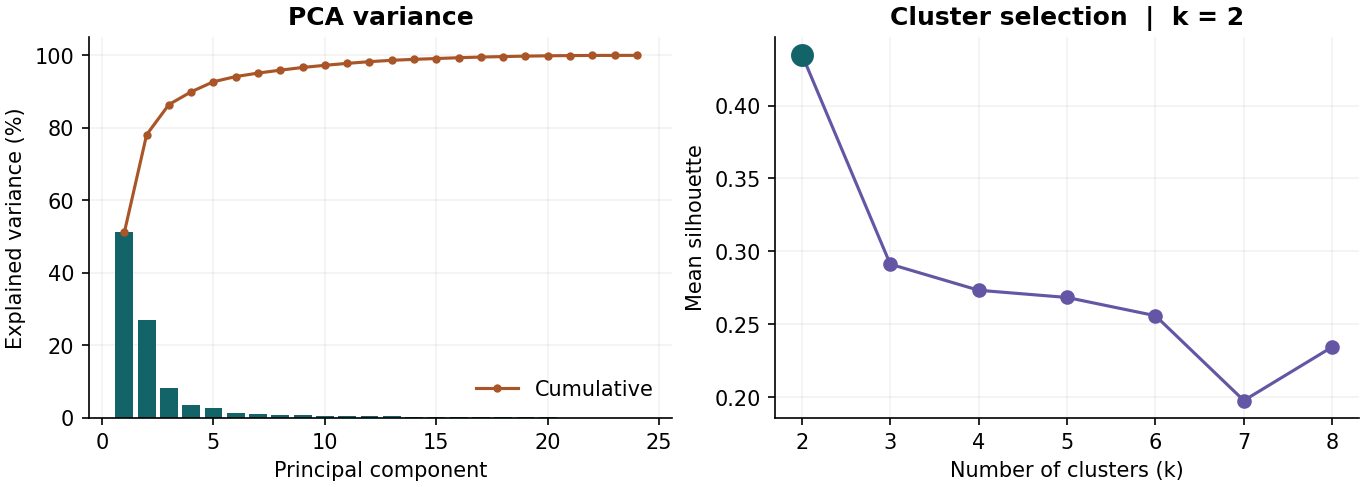

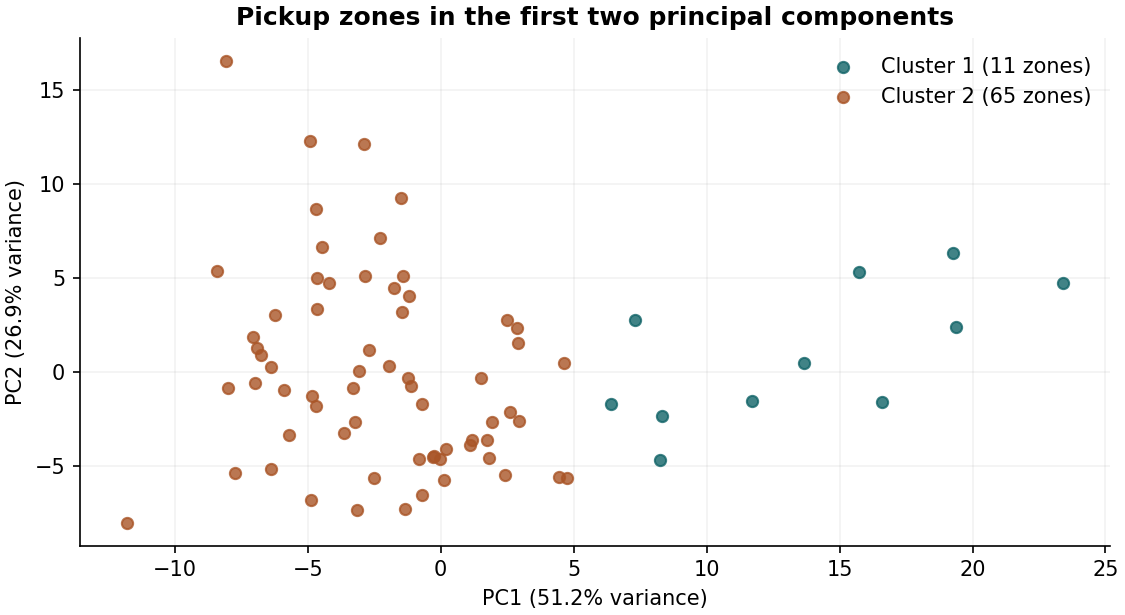

In [3]:
display(table('pca_variance').head(5).round(4))
display(table('cluster_selection').round(4))
show_figure('01_pca_selection.png')
show_figure('02_zone_pca.png')

## Interpretation and stability
The first cluster has a strong late-night signature. The second has more daytime and evening activity. Adjusted Rand index is label-order invariant. The 80% refit assesses the effect of changing the zone sample.

,cluster,zones,training_pickups,peak_hour,share_00_05,share_07_10,share_16_20
0,1,11,170892,0,0.318,0.078,0.227
1,2,65,1699600,17,0.077,0.184,0.304


,cluster,Brooklyn,Manhattan,Queens
0,1,3,8,0
1,2,6,51,8


,mean,median,min,max
check,,,,
80_percent_zones,0.864,1.0,0.063,1.0
different_seed,1.000,1.0,1.000,1.0
standardized_hours,0.993,1.0,0.928,1.0


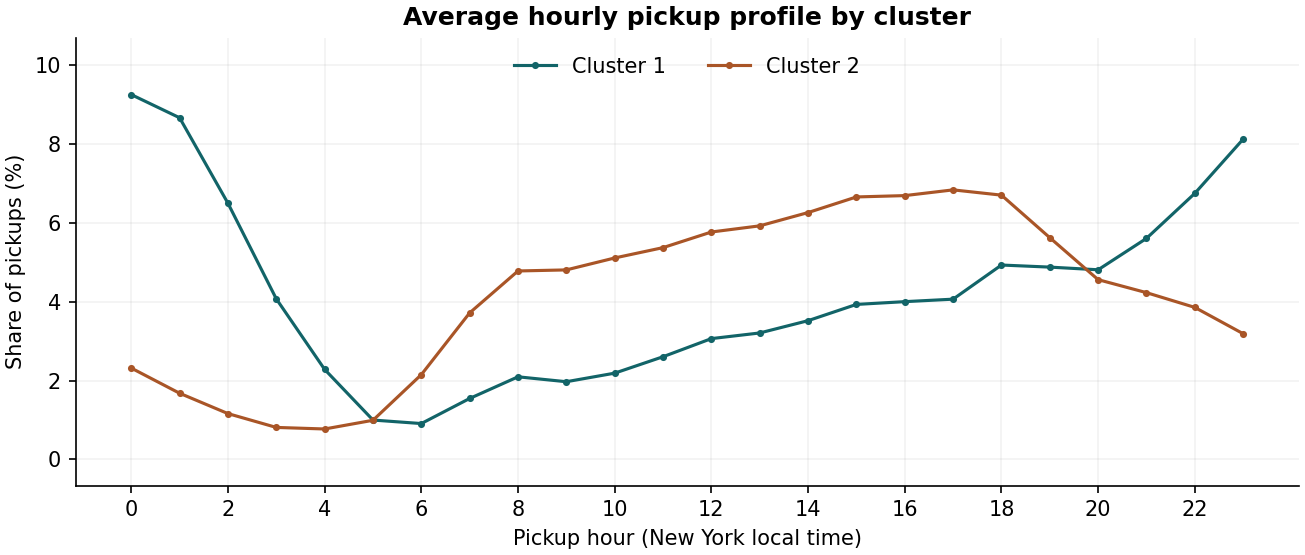

In [4]:
display(table('cluster_summary').round(3))
display(table('cluster_borough_mix'))
stability = table('cluster_stability')
display(stability.groupby('check')['adjusted_rand'].agg(['mean', 'median', 'min', 'max']).round(3))
show_figure('03_cluster_profiles.png')

## Candidate anomalies
Demand candidates use training weekday/weekend-by-hour medians and a training MAD scale. Raw flags may overlap. Event attribution needs independent evidence. The test period is excluded from both screens.

,pickup_hour_start,split,n_trips,expected,residual,robust_z
0,2024-01-01 01:00:00,train,6678,661.0,6017.0,12.21
1,2024-01-01 02:00:00,train,5469,341.0,5128.0,10.40
2,2024-01-01 00:00:00,train,6191,1330.0,4861.0,9.86
3,2024-01-01 03:00:00,train,4371,254.0,4117.0,8.35
4,2024-01-01 18:00:00,train,3534,6938.0,-3404.0,-6.91
5,2024-01-12 23:00:00,train,5972,2662.0,3310.0,6.71
6,2024-01-01 09:00:00,train,1352,4398.0,-3046.0,-6.18
7,2024-01-01 08:00:00,train,1094,4095.0,-3001.0,-6.09


,candidate,train_count,validation_count
0,Non-positive duration,566,220
1,Duration over four hours,1282,431
2,Speed over 80 mph with positive duration,749,252
3,Non-positive distance,42401,13260
4,Non-positive base fare,25609,9270
5,Base fare at least $250,412,131


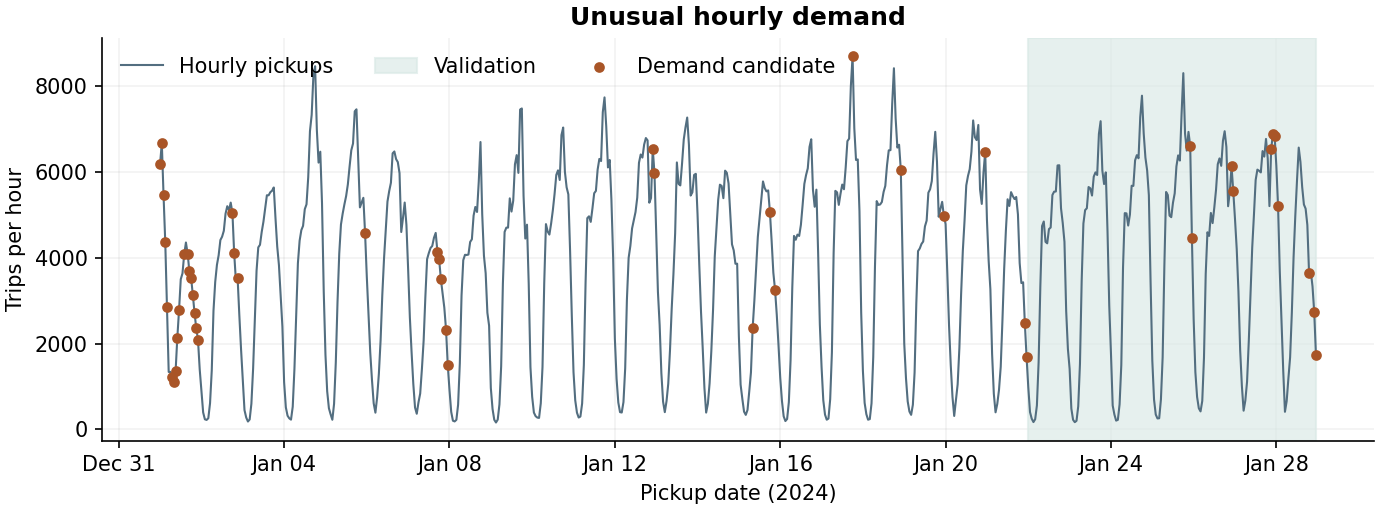

In [5]:
display(table('demand_anomalies').head(8).round(2))
display(table('raw_anomaly_flags'))
show_figure('04_demand_anomalies.png')